<a href="https://colab.research.google.com/github/jayanth3110/quality-scope-manufacturing-analytics/blob/main/QualityScope_Manufacturing_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd

#1. set kaggle credentials (Get these fom your kaggle account -> Settings -> Create New API token)
os.environ['KAGGLE_USERNAME'] = "pabbathijayanth"
os.environ['KAGGLE_KEY'] = "0437782073b48e038c66fe226b21335d"

#2. Download and unzip the dataset
!kaggle datasets download -d rabieelkharoua/predicting-manufacturing-defects-dataset
!unzip -o predicting-manufacturing-defects-dataset.zip

#3. Load into pandas DataFrame
df = pd.read_csv('manufacturing_defect_dataset.csv')
df.head()

Dataset URL: https://www.kaggle.com/datasets/rabieelkharoua/predicting-manufacturing-defects-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 363k/363k [00:00<00:00, 28.8MB/s]

Archive:  predicting-manufacturing-defects-dataset.zip
  inflating: manufacturing_defect_dataset.csv  


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


Phase 1: Production and Quality Data Modeling

In [ ]:
import numpy as np
import pandas as pd
import sqlite3

# 1. Reload the raw dataset to ensure clean columns every time the cell is executed
df = pd.read_csv('manufacturing_defect_dataset.csv')

# Set seed for reproducible synthetic dimension mapping
np.random.seed(42)

# --- STEP 1: GENERATE DIMENSION TABLES (Data Modeling) ---
n_rows = len(df)

lines = ['Line_A', 'Line_B', 'Line_C', 'Line_D']
shifts = ['Day', 'Night']
operators = [f'OP_{i:03d}' for i in range(1, 16)]
skus = [f'SKU_{i:03d}' for i in range(101, 106)]

df['Line_ID'] = np.random.choice(lines, size=n_rows)
df['Shift'] = np.random.choice(shifts, size=n_rows)
df['Operator_ID'] = np.random.choice(operators, size=n_rows)
df['Product_SKU'] = np.random.choice(skus, size=n_rows)
df['Run_ID'] = [f'RUN_{i:05d}' for i in range(1, n_rows + 1)]

# --- STEP 2: CALCULATE CORE QUALITY KPIs ---
df['Defect_PPM'] = df['DefectRate'] * 10_000
df['First_Pass_Yield_Pct'] = 100 - df['DefectRate']

# Total units produced vs defective units
df['Defective_Units'] = np.round((df['DefectRate'] / 100) * df['ProductionVolume']).astype(int)
df['Passed_Units'] = df['ProductionVolume'] - df['Defective_Units']

# Scrap % vs Rework Rate (60% scrapped, 40% reworked)
df['Scrapped_Units'] = np.round(df['Defective_Units'] * 0.60).astype(int)
df['Reworked_Units'] = df['Defective_Units'] - df['Scrapped_Units']

df['Scrap_Rate_Pct'] = (df['Scrapped_Units'] / df['ProductionVolume']) * 100
df['Rework_Rate_Pct'] = (df['Reworked_Units'] / df['ProductionVolume']) * 100

# --- STEP 3: CREATE RELATIONAL DATA MART (SQLite Database) ---
conn = sqlite3.connect('quality_scope_datamart.db')

# Dimension Tables
dim_line = pd.DataFrame({'Line_ID': lines, 'Line_Name': [f'Assembly {l}' for l in lines]})
dim_shift = pd.DataFrame({'Shift': ['Day', 'Night'], 'Start_Time': ['06:00', '18:00']})
dim_operator = pd.DataFrame({'Operator_ID': operators})
dim_sku = pd.DataFrame({'Product_SKU': skus})

dim_line.to_sql('Dim_Line', conn, if_exists='replace', index=False)
dim_shift.to_sql('Dim_Shift', conn, if_exists='replace', index=False)
dim_operator.to_sql('Dim_Operator', conn, if_exists='replace', index=False)
dim_sku.to_sql('Dim_SKU', conn, if_exists='replace', index=False)

# Fact Table
df.to_sql('Fact_Production_Quality', conn, if_exists='replace', index=False)

# --- STEP 4: VERIFY DATA MART WITH KPI SUMMARY QUERY ---
kpi_summary_query = """
SELECT
    Line_ID,
    Shift,
    SUM(ProductionVolume) as Total_Volume,
    SUM(Defective_Units) as Total_Defects,
    ROUND(AVG(First_Pass_Yield_Pct), 2) as Avg_FPY_Pct,
    ROUND(AVG(Defect_PPM), 0) as Avg_Defect_PPM,
    ROUND(AVG(Scrap_Rate_Pct), 2) as Avg_Scrap_Pct,
    ROUND(AVG(Rework_Rate_Pct), 2) as Avg_Rework_Pct
FROM Fact_Production_Quality
GROUP BY Line_ID, Shift
ORDER BY Line_ID, Shift;
"""

summary_df = pd.read_sql_query(kpi_summary_query, conn)
summary_df

,Line_ID,Shift,Total_Volume,Total_Defects,Avg_FPY_Pct,Avg_Defect_PPM,Avg_Scrap_Pct,Avg_Rework_Pct
0,Line_A,Day,227045,6125,97.30,27023.0,1.62,1.07
1,Line_A,Night,234669,6493,97.25,27455.0,1.64,1.10
2,Line_B,Day,210454,5793,97.24,27600.0,1.66,1.10
3,Line_B,Night,241516,6431,97.33,26705.0,1.59,1.07
4,Line_C,Day,226732,6185,97.24,27565.0,1.66,1.10
5,Line_C,Night,207057,5583,97.26,27364.0,1.65,1.09
6,Line_D,Day,217620,6006,97.21,27856.0,1.68,1.11
7,Line_D,Night,212122,6013,97.16,28435.0,1.71,1.13


Phase 2: Defect Pattren Analysis

=== DEFECT PATTERNS BY LINE & SHIFT ===
  Line_ID  Shift  Total_Runs  Total_Defects  Avg_Defect_Rate_Pct  \
0  Line_D  Night         384           6013                 2.84   
1  Line_D    Day         408           6006                 2.79   
2  Line_B    Day         397           5793                 2.76   
3  Line_C    Day         411           6185                 2.76   
4  Line_A  Night         432           6493                 2.75   
5  Line_C  Night         379           5583                 2.74   
6  Line_A    Day         413           6125                 2.70   
7  Line_B  Night         416           6431                 2.67   

   Avg_Supplier_Quality  Avg_Maintenance_Hours  Avg_Worker_Productivity  
0                 89.64                  11.00                    89.91  
1                 90.14                  11.92                    90.63  
2                 89.99                  11.38                    90.49  
3                 90.11                  10.90     

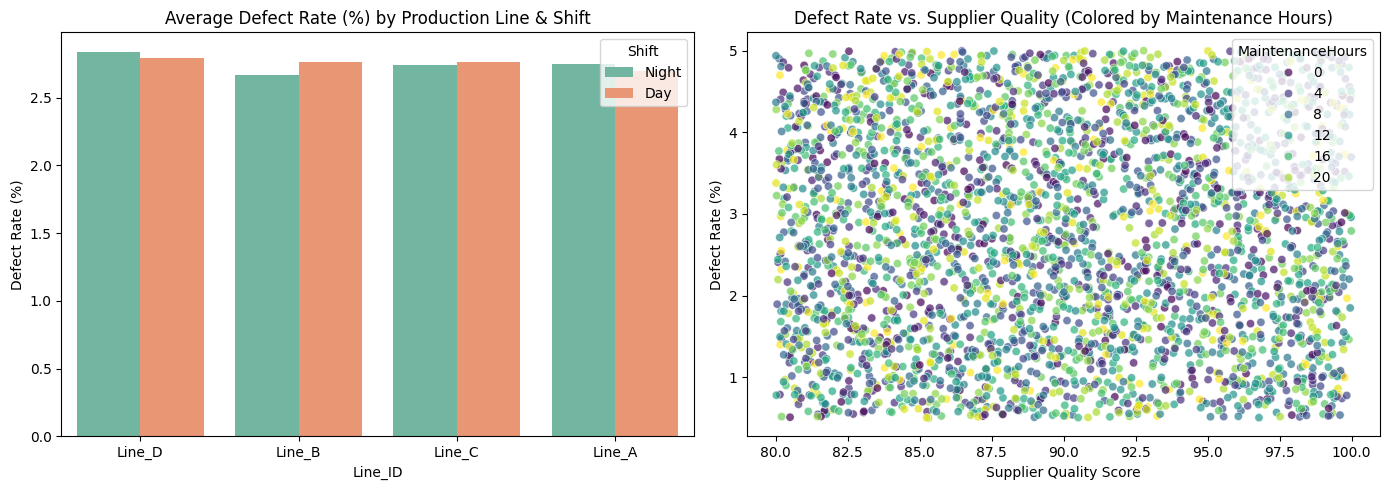

In [ ]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('quality_scope_datamart.db')

# --- STEP 1: DEFECT RISK SEGMENTATION (By Line & Shift) ---
defect_pattern_query = """
SELECT
    Line_ID,
    Shift,
    COUNT(Run_ID) as Total_Runs,
    SUM(Defective_Units) as Total_Defects,
    ROUND(AVG(DefectRate), 2) as Avg_Defect_Rate_Pct,
    ROUND(AVG(SupplierQuality), 2) as Avg_Supplier_Quality,
    ROUND(AVG(MaintenanceHours), 2) as Avg_Maintenance_Hours,
    ROUND(AVG(WorkerProductivity), 2) as Avg_Worker_Productivity
FROM Fact_Production_Quality
GROUP BY Line_ID, Shift
ORDER BY Avg_Defect_Rate_Pct DESC;
"""

pattern_df = pd.read_sql_query(defect_pattern_query, conn)
print("=== DEFECT PATTERNS BY LINE & SHIFT ===")
print(pattern_df)

# --- STEP 2: SUPPLIER MATERIAL QUALITY IMPACT ANALYSIS ---
supplier_impact_query = """
SELECT
    CASE
        WHEN SupplierQuality >= 90 THEN 'High Quality (>=90)'
        WHEN SupplierQuality >= 80 THEN 'Medium Quality (80-89)'
        ELSE 'Low Quality (<80)'
    END as Supplier_Tier,
    COUNT(Run_ID) as Run_Count,
    ROUND(AVG(DefectRate), 2) as Avg_Defect_Rate_Pct,
    ROUND(AVG(First_Pass_Yield_Pct), 2) as Avg_FPY_Pct
FROM Fact_Production_Quality
GROUP BY Supplier_Tier
ORDER BY Avg_Defect_Rate_Pct DESC;
"""

supplier_df = pd.read_sql_query(supplier_impact_query, conn)
print("\n=== SUPPLIER MATERIAL IMPACT ON YIELD ===")
print(supplier_df)

# --- STEP 3: VISUALIZE DEFECT PATTERNS & MAINTENANCE CORRELATION ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Defect Rate by Line and Shift
sns.barplot(
    data=pattern_df,
    x='Line_ID',
    y='Avg_Defect_Rate_Pct',
    hue='Shift',
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Average Defect Rate (%) by Production Line & Shift')
axes[0].set_ylabel('Defect Rate (%)')

# Plot 2: Defect Rate vs Supplier Quality
fact_df = pd.read_sql_query("SELECT SupplierQuality, DefectRate, MaintenanceHours FROM Fact_Production_Quality", conn)
sns.scatterplot(
    data=fact_df,
    x='SupplierQuality',
    y='DefectRate',
    hue='MaintenanceHours',
    palette='viridis',
    ax=axes[1],
    alpha=0.7
)
axes[1].set_title('Defect Rate vs. Supplier Quality (Colored by Maintenance Hours)')
axes[1].set_xlabel('Supplier Quality Score')
axes[1].set_ylabel('Defect Rate (%)')

plt.tight_layout()
plt.show()

Phase 3: Yeild Optimization Intelligence


In [ ]:
import pandas as pd
import numpy as np
import sqlite3

conn = sqlite3.connect('quality_scope_datamart.db')
df = pd.read_sql_query("SELECT * FROM Fact_Production_Quality", conn)

# 1. FLAG HIGH-RISK RUNS
high_risk_condition = (
    (df['DefectRate'] > 4.0) |
    (df['DowntimePercentage'] > 4.0) |
    (df['SupplierQuality'] < 82.0)
)
df['Risk_Level'] = np.where(high_risk_condition, 'HIGH RISK (Escalate)', 'NORMAL')

# 2. GENERATE PREVENTIVE ACTION COLUMN
def generate_preventive_action(row):
    actions = []
    if row['SupplierQuality'] < 82:
        actions.append("Inspect raw material batch / Switch supplier tier")
    if row['MaintenanceHours'] < 5:
        actions.append("Schedule immediate PM (Preventive Maintenance) check")
    if row['DowntimePercentage'] > 4.0:
        actions.append("Calibrate tooling and check motor drive alignment")
    if row['WorkerProductivity'] < 85:
        actions.append("Review shift staffing & operator SOP compliance")

    return " | ".join(actions) if actions else "Optimal Conditions - Proceed"

df['Preventive_Action'] = df.apply(generate_preventive_action, axis=1)

# 3. SAVE TO SQLITE AND EXPORT ENRICHED CSV FILES FOR POWER BI
df.to_sql('Fact_Production_Quality', conn, if_exists='replace', index=False)

dim_line = pd.read_sql_query("SELECT * FROM Dim_Line", conn)
dim_shift = pd.read_sql_query("SELECT * FROM Dim_Shift", conn)
dim_operator = pd.read_sql_query("SELECT * FROM Dim_Operator", conn)
dim_sku = pd.read_sql_query("SELECT * FROM Dim_SKU", conn)

df.to_csv('Fact_Production_Quality.csv', index=False)
dim_line.to_csv('Dim_Line.csv', index=False)
dim_shift.to_csv('Dim_Shift.csv', index=False)
dim_operator.to_csv('Dim_Operator.csv', index=False)
dim_sku.to_csv('Dim_SKU.csv', index=False)

print("Success! Download 'Fact_Production_Quality.csv' and hit 'Refresh' in Power BI.")

Success! Download 'Fact_Production_Quality.csv' and hit 'Refresh' in Power BI.


Phase 4 : Plant Quality Dashboard


In [ ]:
import pandas as pd
import sqlite3

conn = sqlite3.connect('quality_scope_datamart.db')

# --- STEP 1: SHIFT-LEVEL QUALITY CONTROL SUMMARY REPORT ---
shift_summary_query = """
SELECT
    Line_ID,
    Shift,
    COUNT(Run_ID) as Total_Runs,
    SUM(ProductionVolume) as Total_Volume,
    SUM(Defective_Units) as Total_Defects,
    SUM(Scrapped_Units) as Total_Scrapped,
    SUM(Reworked_Units) as Total_Reworked,
    ROUND(AVG(First_Pass_Yield_Pct), 2) as Avg_FPY_Pct,
    ROUND(AVG(Defect_PPM), 0) as Avg_Defect_PPM,
    SUM(CASE WHEN Risk_Level = 'HIGH RISK (Escalate)' THEN 1 ELSE 0 END) as High_Risk_Runs
FROM Fact_Production_Quality
GROUP BY Line_ID, Shift
ORDER BY Line_ID, Shift;
"""

shift_summary_df = pd.read_sql_query(shift_summary_query, conn)
print("=== PLANT QUALITY CONTROL BOARD (Shift Summary) ===")
print(shift_summary_df)

# --- STEP 2: EXPORT ENRICHED DATA MART TO CSV FOR POWER BI / TABLEAU ---
fact_df = pd.read_sql_query("SELECT * FROM Fact_Production_Quality", conn)
dim_line = pd.read_sql_query("SELECT * FROM Dim_Line", conn)
dim_shift = pd.read_sql_query("SELECT * FROM Dim_Shift", conn)
dim_operator = pd.read_sql_query("SELECT * FROM Dim_Operator", conn)
dim_sku = pd.read_sql_query("SELECT * FROM Dim_SKU", conn)

# Export tables
fact_df.to_csv('Fact_Production_Quality.csv', index=False)
dim_line.to_csv('Dim_Line.csv', index=False)
dim_shift.to_csv('Dim_Shift.csv', index=False)
dim_operator.to_csv('Dim_Operator.csv', index=False)
dim_sku.to_csv('Dim_SKU.csv', index=False)

print("\n Files successfully exported as CSVs for Power BI / Tableau!")

=== PLANT QUALITY CONTROL BOARD (Shift Summary) ===
  Line_ID  Shift  Total_Runs  Total_Volume  Total_Defects  Total_Scrapped  \
0  Line_A    Day         413        227045           6125            3678   
1  Line_A  Night         432        234669           6493            3896   
2  Line_B    Day         397        210454           5793            3481   
3  Line_B  Night         416        241516           6431            3848   
4  Line_C    Day         411        226732           6185            3723   
5  Line_C  Night         379        207057           5583            3351   
6  Line_D    Day         408        217620           6006            3608   
7  Line_D  Night         384        212122           6013            3616   

   Total_Reworked  Avg_FPY_Pct  Avg_Defect_PPM  High_Risk_Runs  
0            2447        97.30         27023.0             173  
1            2597        97.25         27455.0             201  
2            2312        97.24         27600.0             